# 01 — Análisis exploratorio de datos (EDA)

**Escenario 4:** Efectividad de campañas de marketing
**Dataset:** Bank Marketing (UCI) — `bank-additional-full.csv`
**Fuente:** Moro, Cortez & Rita (2014). Son datos de campañas de telemarketing de un banco de Portugal, entre mayo de 2008 y noviembre de 2010.

En este notebook se revisa el dataset antes de hacer cualquier modelo. La idea es ver cómo están los datos, si tienen errores o datos faltantes y qué cosas hay que arreglar en el preprocesamiento.

## 0. Librerías y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/raw/bank-additional-full.csv", sep=";")
print(f"Registros: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Registros: 41,188 | Columnas: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1. Estructura del dataset

Según el archivo `bank-additional-names.txt`, las variables se pueden separar en estos grupos:

| Grupo | Variables |
|---|---|
| Datos del cliente | `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` |
| Último contacto de la campaña actual | `contact`, `month`, `day_of_week`, `duration` |
| Campañas anteriores | `campaign`, `pdays`, `previous`, `poutcome` |
| Datos económicos del país | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` |
| **Variable objetivo** | `y`: si el cliente contrató el depósito a plazo (yes/no) |

In [2]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols and c != "y"]

print(f"Numéricas ({len(num_cols)}): {num_cols}")
print(f"Categóricas ({len(cat_cols)}): {cat_cols}")
print("Objetivo: y")
df.info()

Numéricas (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categóricas (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Objetivo: y
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non

## 2. Estadísticas descriptivas

Primero se revisan los valores básicos de las variables numéricas (promedio, mínimo, máximo, etc.) y después la categoría que más se repite en cada variable categórica.

In [3]:
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


In [4]:
resumen_cat = pd.DataFrame({
    "n_categorias": df[cat_cols].nunique(),
    "moda": df[cat_cols].mode().iloc[0],
    "frecuencia_moda_%": [(df[c].value_counts(normalize=True).iloc[0] * 100).round(1) for c in cat_cols],
})
resumen_cat

,n_categorias,moda,frecuencia_moda_%
job,12,admin.,25.3
marital,4,married,60.5
education,8,university.degree,29.5
default,3,no,79.1
housing,3,yes,52.4
loan,3,no,82.4
contact,2,cellular,63.5
month,10,may,33.4
day_of_week,5,thu,20.9
poutcome,3,nonexistent,86.3


## 3. Calidad de los datos: nulos, 'unknown' y duplicados

Al revisar se encontró que el dataset no tiene valores `NaN`, pero en las variables categóricas los datos que faltan aparecen como **`unknown`**, así que en la práctica sí hay datos faltantes.

También en `pdays` el valor 999 no es un número real, significa que al cliente **nunca lo contactaron antes**.

In [5]:
print("Valores NaN totales:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

unknown = (df[cat_cols] == "unknown").sum()
unknown = unknown[unknown > 0].sort_values(ascending=False)
unknown_pct = (unknown / len(df) * 100).round(2)
tabla_unknown = pd.DataFrame({"cantidad": unknown, "porcentaje_%": unknown_pct})
tabla_unknown

Valores NaN totales: 0


Filas duplicadas: 12


,cantidad,porcentaje_%
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


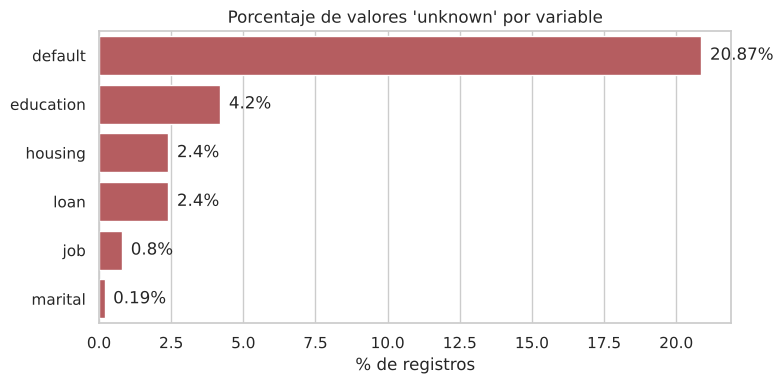

pdays = 999 (nunca contactado): 96.3%
Valores de default: {'no': 32588, 'unknown': 8597, 'yes': 3}


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=tabla_unknown["porcentaje_%"], y=tabla_unknown.index, ax=ax, color="#C44E52")
for i, v in enumerate(tabla_unknown["porcentaje_%"]):
    ax.text(v + 0.3, i, f"{v}%", va="center")
ax.set_title("Porcentaje de valores 'unknown' por variable")
ax.set_xlabel("% de registros")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

print(f"pdays = 999 (nunca contactado): {(df['pdays'] == 999).mean() * 100:.1f}%")
print("Valores de default:", df["default"].value_counts().to_dict())

## 4. Variable objetivo `y`

Se revisa cuántos clientes dijeron que sí y cuántos que no.

     cantidad  porcentaje_%
y                          
no      36548         88.73
yes      4640         11.27


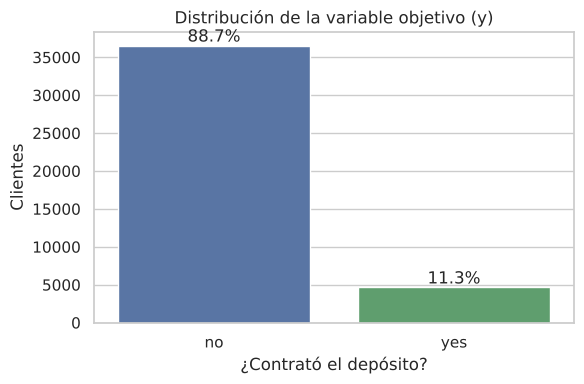

Ratio de desbalance: 7.9 : 1


In [7]:
conteo = df["y"].value_counts()
pct = df["y"].value_counts(normalize=True) * 100
print(pd.DataFrame({"cantidad": conteo, "porcentaje_%": pct.round(2)}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="y", order=["no", "yes"], ax=ax, palette=["#4C72B0", "#55A868"])
for p, v in zip(ax.patches, pct[["no", "yes"]]):
    ax.annotate(f"{v:.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Distribución de la variable objetivo (y)")
ax.set_xlabel("¿Contrató el depósito?")
ax.set_ylabel("Clientes")
plt.tight_layout()
plt.show()
print(f"Ratio de desbalance: {conteo['no'] / conteo['yes']:.1f} : 1")

## 5. Distribución de las variables numéricas

Con histogramas se ve cómo se reparten los valores, y con boxplots se compara cada variable entre los que dijeron sí y no. Al final se cuentan los valores atípicos con el método IQR.

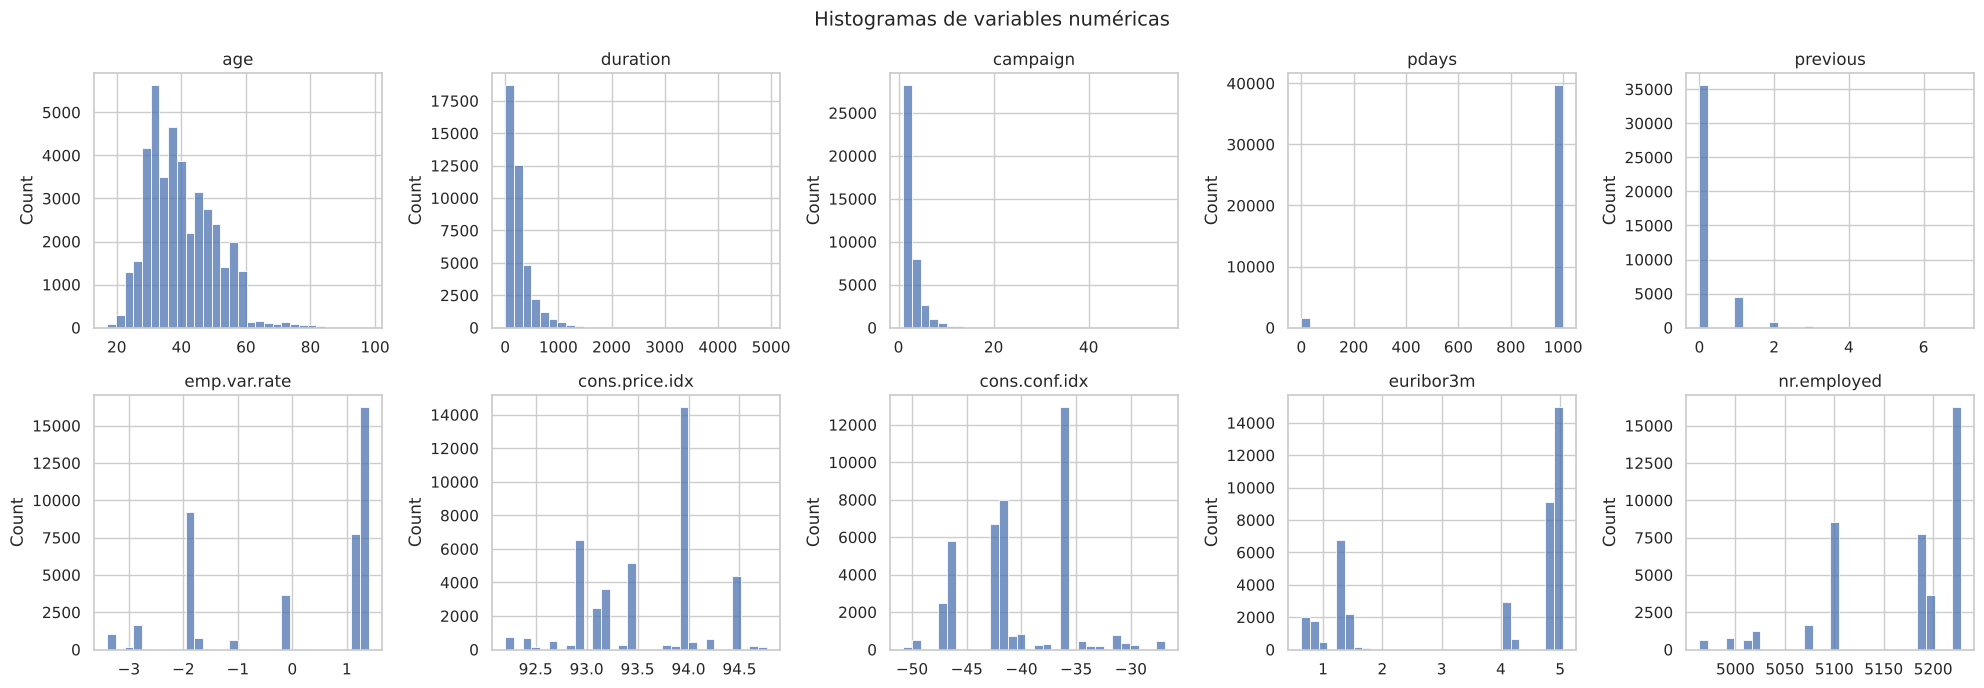

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=30, ax=ax, color="#4C72B0")
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Histogramas de variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

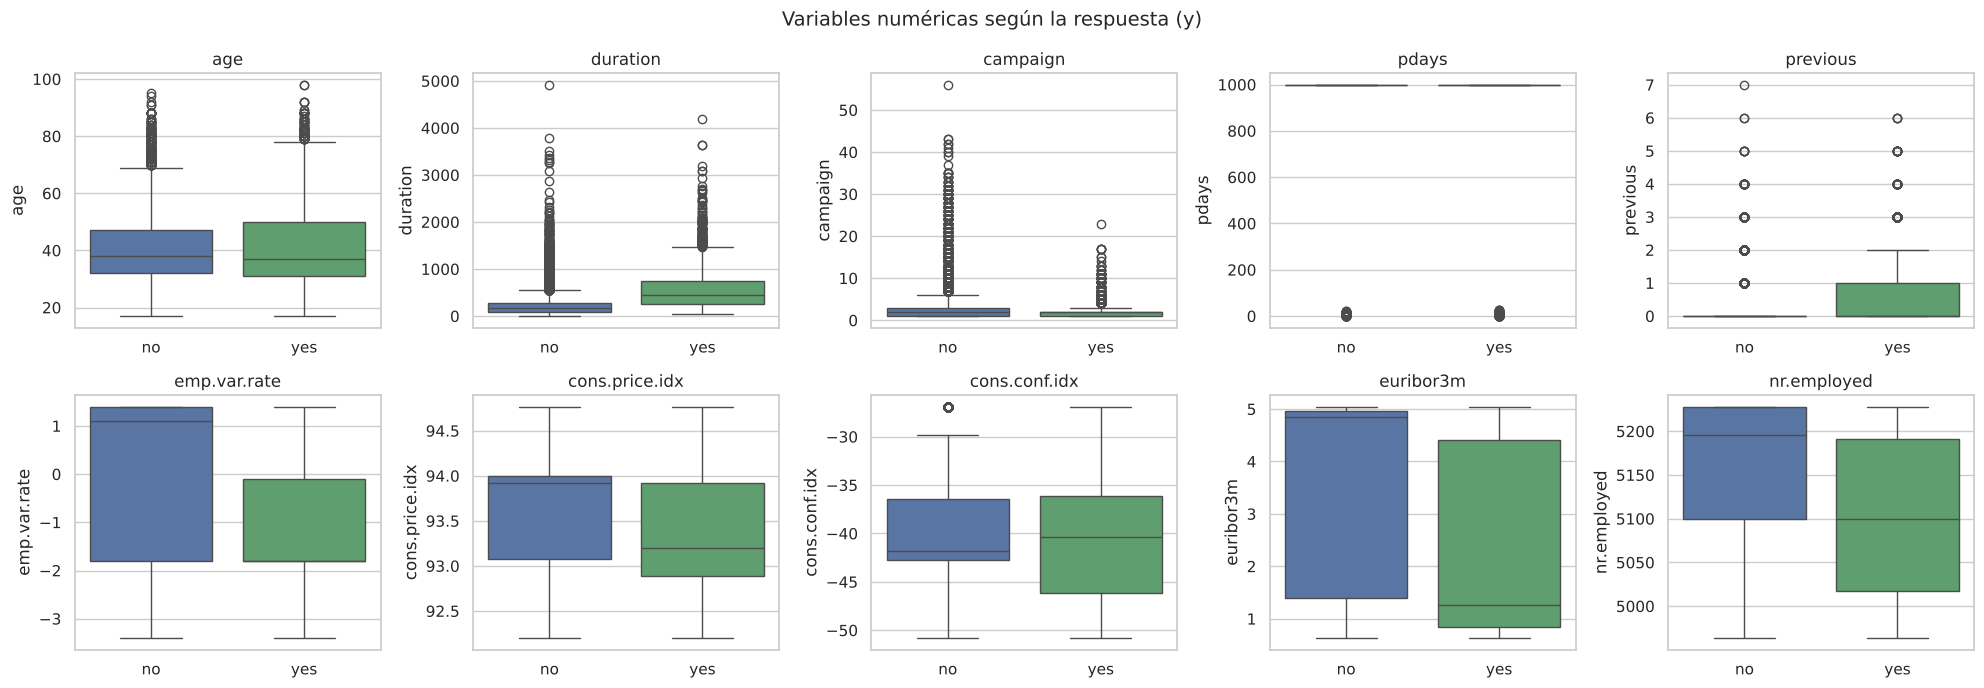

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="y", y=col, ax=ax, order=["no", "yes"], palette=["#4C72B0", "#55A868"])
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Variables numéricas según la respuesta (y)", fontsize=14)
plt.tight_layout()
plt.show()

In [10]:
# Valores atípicos con el criterio IQR (1.5 x rango intercuartílico)
def outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.Series({c: outliers_iqr(df[c]) for c in num_cols if c != "pdays"})
pd.DataFrame({"outliers": out, "porcentaje_%": (out / len(df) * 100).round(2)}).sort_values("outliers", ascending=False)

,outliers,porcentaje_%
previous,5625,13.66
duration,2963,7.19
campaign,2406,5.84
age,469,1.14
cons.conf.idx,447,1.09
emp.var.rate,0,0.00
cons.price.idx,0,0.00
euribor3m,0,0.00
nr.employed,0,0.00


## 6. Distribución de las variables categóricas

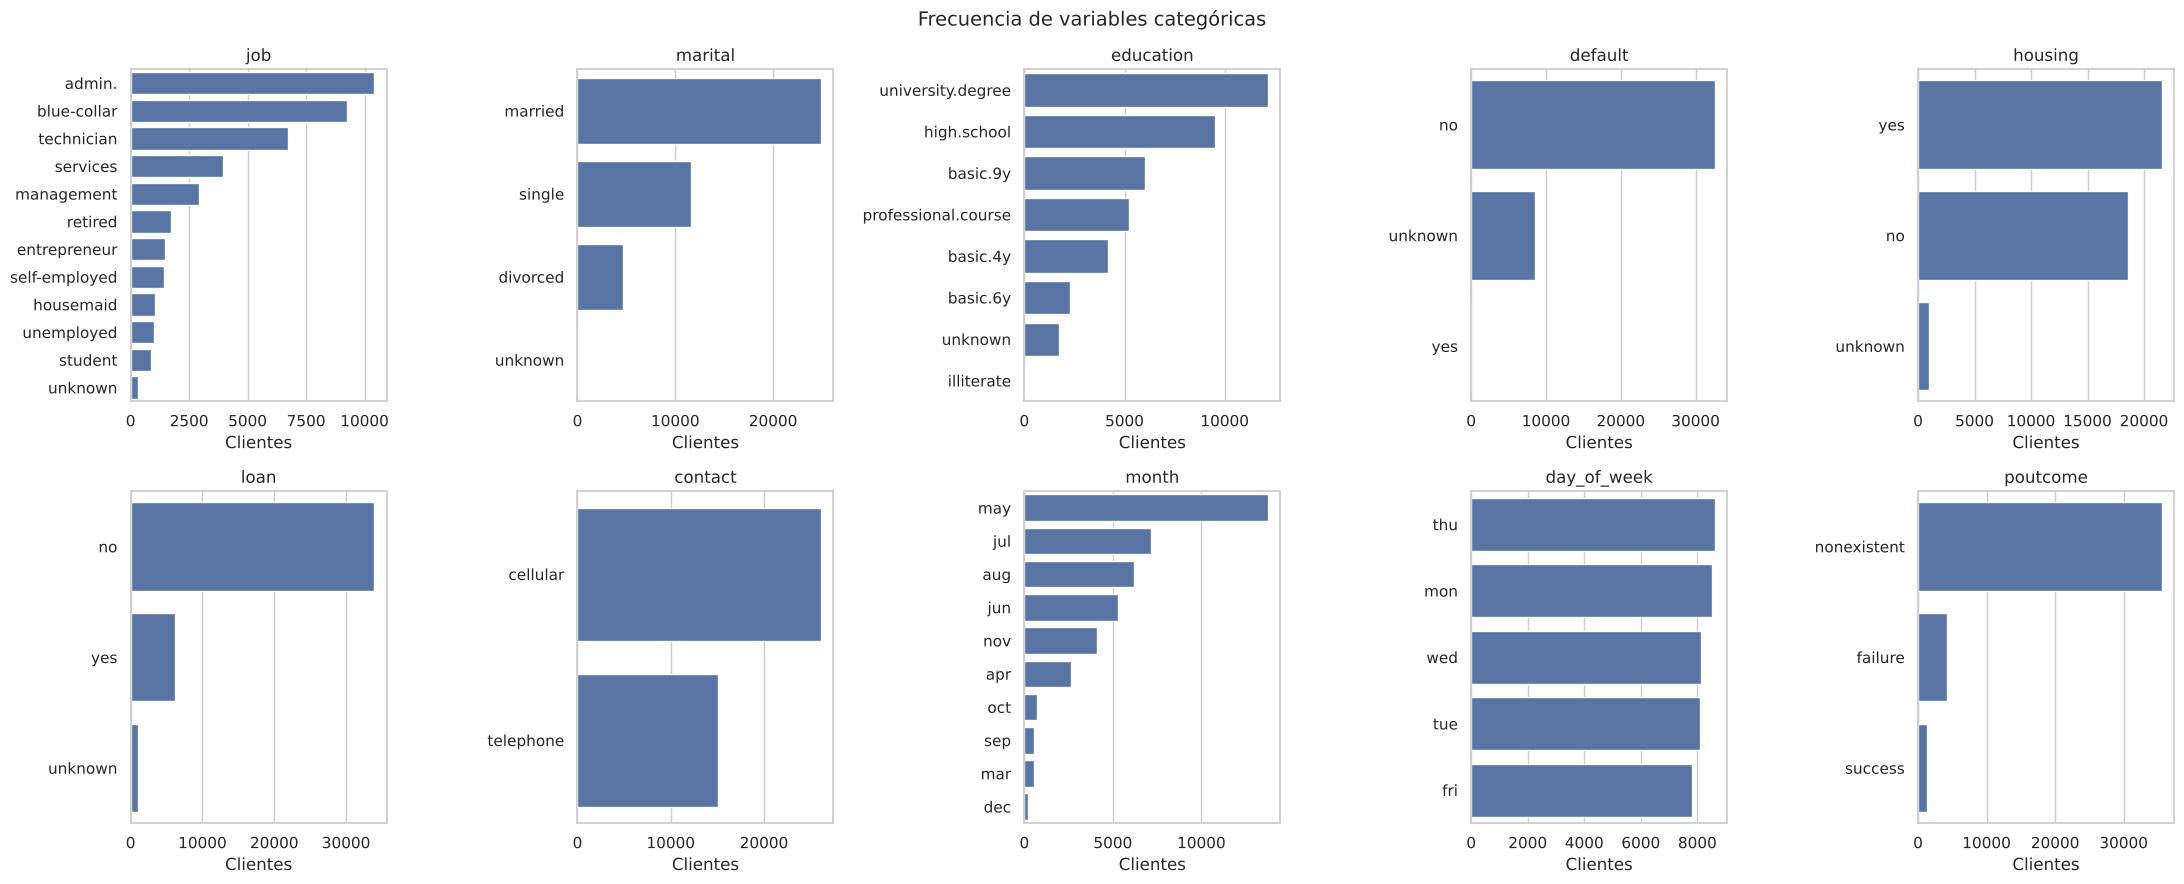

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, col in zip(axes.flat, cat_cols):
    orden = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=orden, ax=ax, color="#4C72B0")
    ax.set_title(col)
    ax.set_xlabel("Clientes")
    ax.set_ylabel("")
fig.suptitle("Frecuencia de variables categóricas", fontsize=14)
plt.tight_layout()
plt.show()

## 7. Tasa de conversión por variable categórica

Aquí se calcula qué porcentaje de clientes dijo **yes** en cada categoría. La línea punteada es el porcentaje general (11,3%), así se puede ver qué grupos están por encima o por debajo.

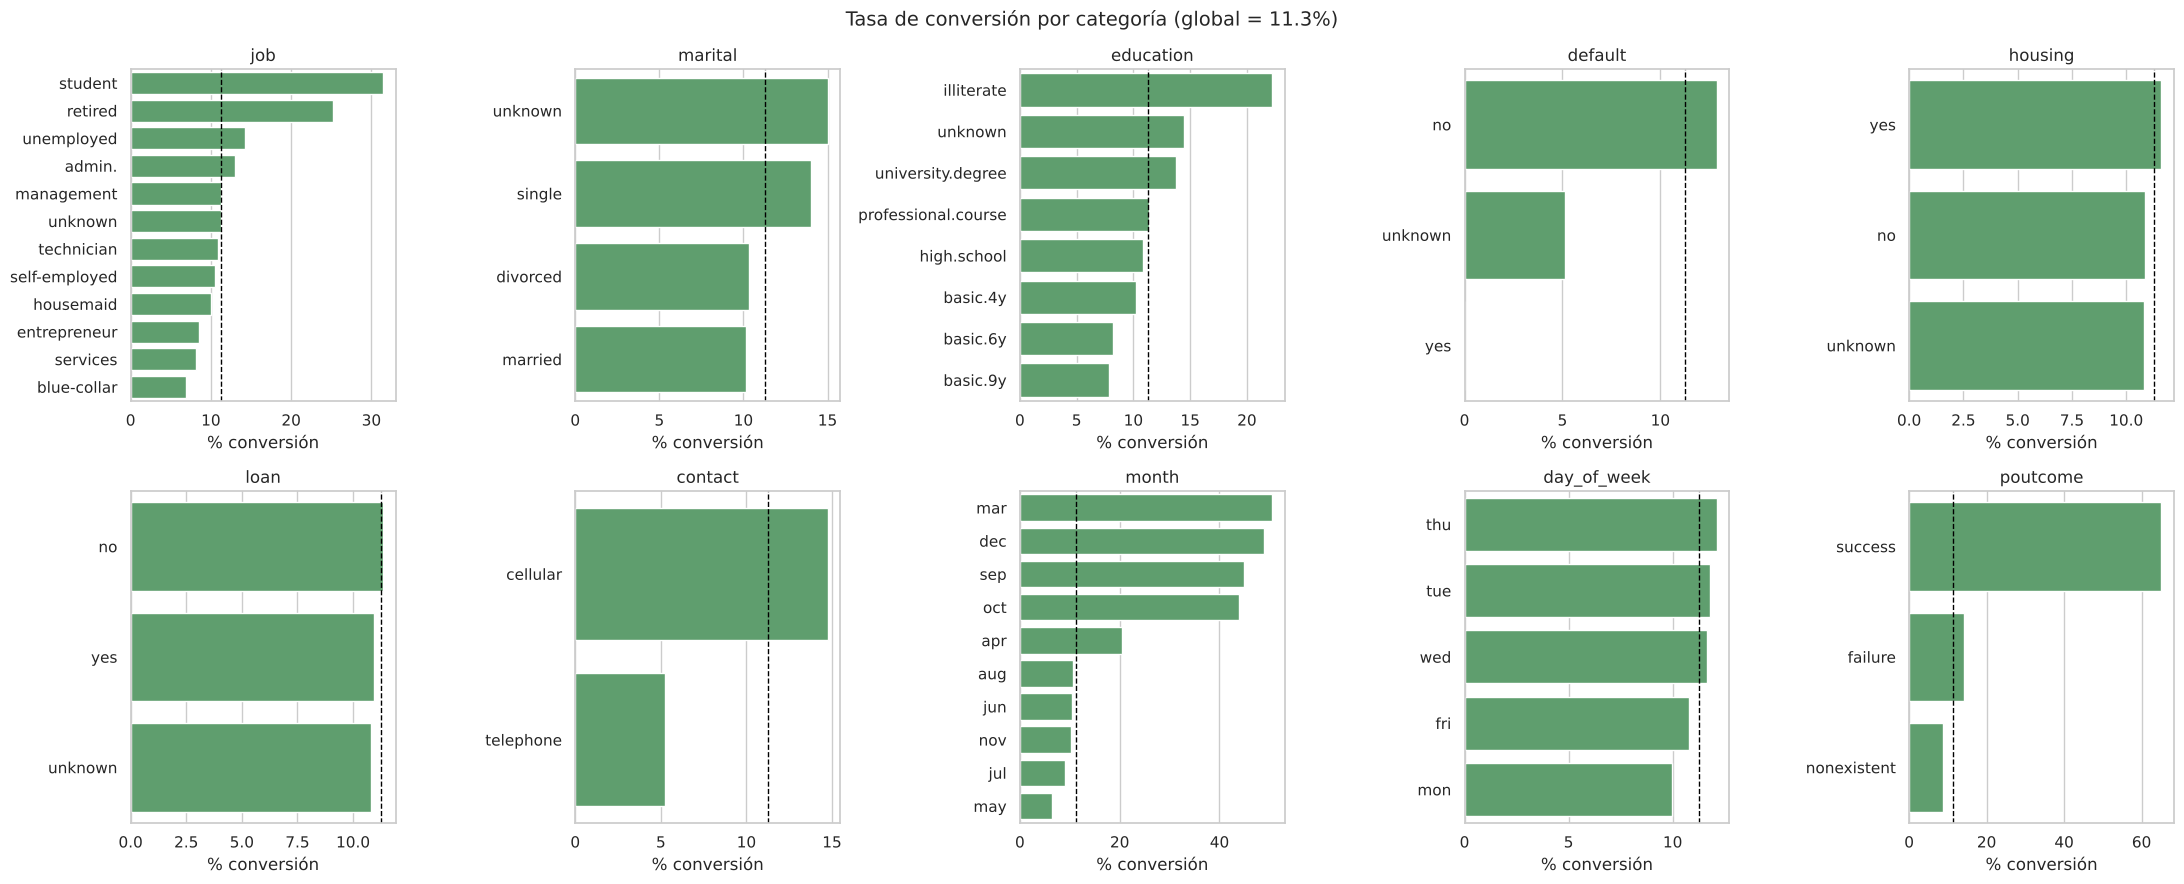

In [12]:
df["y_bin"] = (df["y"] == "yes").astype(int)
tasa_global = df["y_bin"].mean() * 100

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, col in zip(axes.flat, cat_cols):
    tasa = df.groupby(col)["y_bin"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=tasa.values, y=tasa.index, ax=ax, color="#55A868")
    ax.axvline(tasa_global, ls="--", color="black", lw=1)
    ax.set_title(col)
    ax.set_xlabel("% conversión")
    ax.set_ylabel("")
fig.suptitle(f"Tasa de conversión por categoría (global = {tasa_global:.1f}%)", fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
for col in ["poutcome", "contact", "month", "job"]:
    t = df.groupby(col)["y_bin"].agg(clientes="count", conversion="mean")
    t["conversion"] = (t["conversion"] * 100).round(1)
    print(f"\n--- {col} ---")
    print(t.sort_values("conversion", ascending=False))


--- poutcome ---
             clientes  conversion
poutcome                         
success          1373        65.1
failure          4252        14.2
nonexistent     35563         8.8

--- contact ---
           clientes  conversion
contact                        
cellular      26144        14.7
telephone     15044         5.2

--- month ---
       clientes  conversion
month                      
mar         546        50.5
dec         182        48.9
sep         570        44.9
oct         718        43.9
apr        2632        20.5
aug        6178        10.6
jun        5318        10.5
nov        4101        10.1
jul        7174         9.0
may       13769         6.4

--- job ---
               clientes  conversion
job                                
student             875        31.4
retired            1720        25.2
unemployed         1014        14.2
admin.            10422        13.0
unknown             330        11.2
management         2924        11.2
technician     

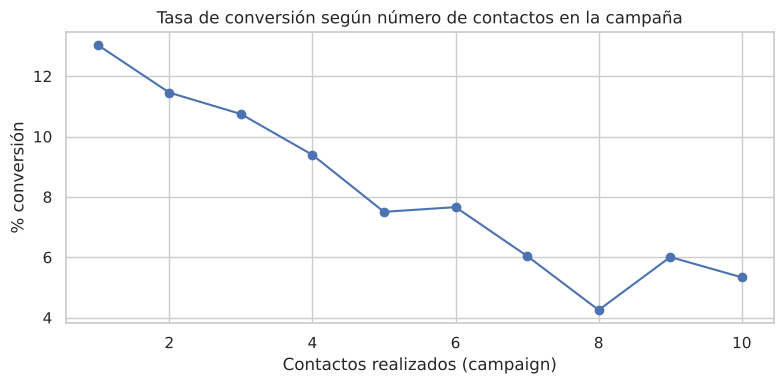

In [14]:
# Efecto del número de contactos en la campaña actual
camp = df[df["campaign"] <= 10].groupby("campaign")["y_bin"].mean().mul(100)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(camp.index, camp.values, marker="o", color="#4C72B0")
ax.set_title("Tasa de conversión según número de contactos en la campaña")
ax.set_xlabel("Contactos realizados (campaign)")
ax.set_ylabel("% conversión")
plt.tight_layout()
plt.show()

## 8. Correlaciones

Se usa la correlación de Pearson para ver qué variables numéricas se relacionan entre sí y con `y`.

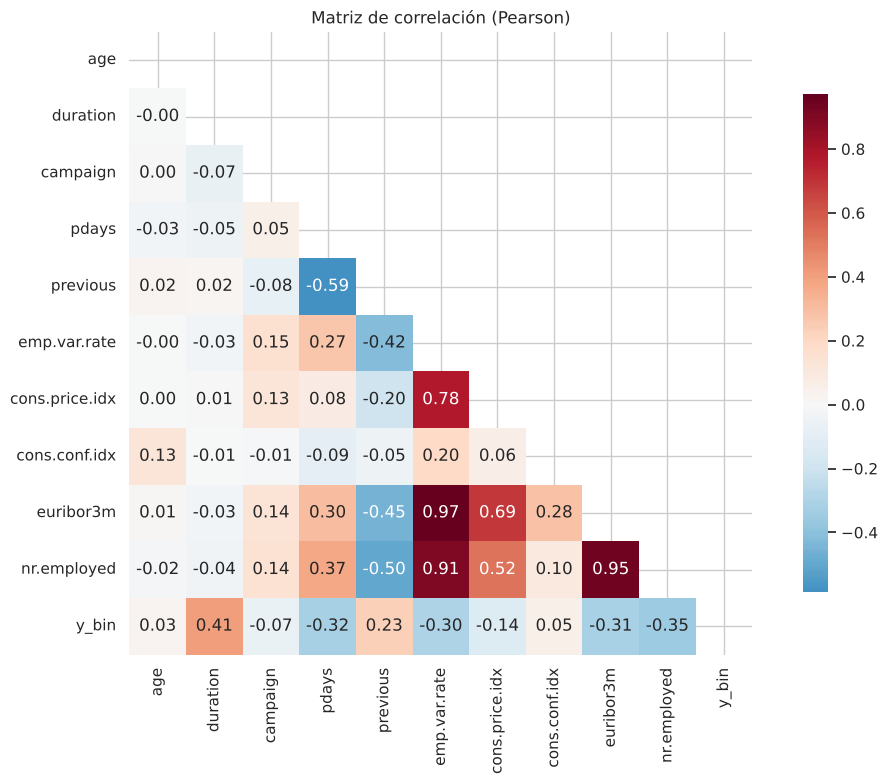

In [15]:
corr = df[num_cols + ["y_bin"]].corr()
fig, ax = plt.subplots(figsize=(11, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, square=True, cbar_kws={"shrink": 0.8})
ax.set_title("Matriz de correlación (Pearson)")
plt.tight_layout()
plt.show()

In [16]:
print("Correlación de cada variable con y:")
print(corr["y_bin"].drop("y_bin").sort_values(key=abs, ascending=False).round(3))

pares = corr.drop(index="y_bin", columns="y_bin").where(np.triu(np.ones((10, 10)), 1).astype(bool)).stack()
print("\nPares muy correlacionados (|r| > 0.7):")
print(pares[pares.abs() > 0.7].sort_values(key=abs, ascending=False).round(3))

Correlación de cada variable con y:
duration          0.405
nr.employed      -0.355
pdays            -0.325
euribor3m        -0.308
emp.var.rate     -0.298
previous          0.230
cons.price.idx   -0.136
campaign         -0.066
cons.conf.idx     0.055
age               0.030
Name: y_bin, dtype: float64

Pares muy correlacionados (|r| > 0.7):
emp.var.rate  euribor3m         0.972
euribor3m     nr.employed       0.945
emp.var.rate  nr.employed       0.907
              cons.price.idx    0.775
dtype: float64


## 9. Conclusiones del EDA

**Cosas que hay que arreglar en el preprocesamiento (notebook 02):**

1. No hay `NaN`, pero sí hay datos faltantes escritos como `unknown`: `default` (20,9%), `education` (4,2%), `housing` y `loan` (2,4%), `job` (0,8%) y `marital` (0,2%). Hay que decidir si se reemplazan o se dejan como una categoría más.
2. La variable `default` casi no sirve porque solo hay **3** clientes con `yes`, todos los demás son `no` o `unknown`.
3. Hay **12 filas duplicadas** que hay que eliminar.
4. En `pdays` el 96,3% de los registros tiene 999 (nunca contactado), por eso es mejor convertirla en una variable de sí/no.
5. `duration` es la variable que más se relaciona con `y` (0,41), pero la duración de la llamada solo se sabe cuando la llamada ya terminó, entonces no se puede usar para predecir antes de llamar. Por eso se va a sacar del modelo, como recomiendan los autores del dataset.
6. `emp.var.rate`, `euribor3m` y `nr.employed` están muy correlacionadas entre sí (más de 0,90). Esto puede afectar a Naive Bayes porque supone que las variables son independientes, y también es una razón para usar PCA.
7. Las variables tienen escalas muy distintas (por ejemplo `nr.employed` está cerca de 5.000 y `previous` va de 0 a 7), así que hay que estandarizarlas antes de aplicar PCA.
8. Hay valores atípicos en `campaign`, `previous` y `age`, pero son datos reales y no errores, así que se mantienen.

**Sobre la variable objetivo:**

9. Los datos están desbalanceados: 88,7% dijo `no` y solo 11,3% dijo `yes` (más o menos 8 a 1). Si un modelo dijera "no" a todos tendría 88,7% de accuracy sin aprender nada, por eso también se van a usar precision, recall, F1 y ROC-AUC.

**Otros hallazgos (sirven para el aprendizaje por refuerzo):**

10. Los clientes que ya aceptaron en una campaña anterior (`poutcome = success`) aceptan mucho más: 65,1%, contra 8,8% de los que nunca fueron contactados.
11. Llamar al celular funciona mejor que al teléfono fijo: 14,7% contra 5,2%.
12. Mientras más veces se llama a un cliente (`campaign`), menos probable es que acepte.
13. Los estudiantes (31,4%) y jubilados (25,2%) son los que más aceptan. Los que menos aceptan son los obreros (*blue-collar*, 6,9%).
14. En marzo, septiembre, octubre y diciembre la conversión pasa el 40%, pero en mayo, que es el mes donde más se llamó, solo llega a 6,4%.
15. Cuando el euríbor y el número de empleados son más bajos, más clientes aceptan el depósito.